# 3. Tracking data I: simulating measurements

> Simulate one week of DSN range and range-rate tracking of the truth trajectory, inspect the measurement files, and verify the simulated noise.
>
> ⏱ ~10 min &nbsp;·&nbsp; **Prereqs:** [2. Truth: dynamics & propagation](02_truth_dynamics.ipynb) &nbsp;·&nbsp; **Uses:** `outputs/02_truth_dynamics/truth.bsp` &nbsp;·&nbsp; **Produces:** `outputs/03_tracking_data/*.json` &nbsp;·&nbsp; **Next:** [4. The filter's dynamics model](04_filter_dynamics.ipynb)

Measurements in Scarabaeus are organized around files: a measurement model writes observations to a file, and the filters read observations back from files. Simulated data and real tracking data therefore enter the filter the same way. This chapter produces the simulated dataset used in chapters [4](04_filter_dynamics.ipynb)–[7](07_sequential_filtering.ipynb).

## Setup

The scenario from [chapter 1](01_scenario.ipynb), imported from [`scenario.py`](scenario.py), plus the truth trajectory from [chapter 2](02_truth_dynamics.ipynb). Only the truth spacecraft's SPICE ID is needed here; its physical properties matter only for the dynamics.

**Starting here?** This chapter reads the truth trajectory produced by chapter 2. Run `python prepare.py 03` from `tutorials/v2/` to generate it (about 10 s); the setup cell stops with a message if it is missing.

In [1]:
import json
import shutil
from pathlib import Path

import matplotlib.pyplot as plt
import scarabaeus as scb

from scenario import (
    km, m, mm, sec, minute, day,     # units
    epochs, orex, stations,          # tracking arc, truth spacecraft, DSN stations (ch. 1)
)

out = Path("outputs/03_tracking_data")
shutil.rmtree(out, ignore_errors=True)
out.mkdir(parents=True)

# Inputs from earlier chapters. Starting here? Run `python prepare.py 03` first.
if not Path("outputs/02_truth_dynamics/truth.bsp").exists():
    raise FileNotFoundError("This chapter reads the truth trajectory from chapter 2. Run chapter 2, "
                            "or `python prepare.py 03` from tutorials/v2/ (about 10 s).")

scb.SpiceManager.load_kernel("outputs/02_truth_dynamics/truth.bsp")  # truth (ch. 2)


## 1. Measurement models

A measurement model combines an observable type, an instrument (here, a ground station) and a noise level. We use two observables per DSN complex:

- `RangeIdeal`: range $\rho = \lVert \mathbf{r}_{sc} - \mathbf{r}_{gs} \rVert$, σ = 2 m;
- `RangeRateIdeal`: line-of-sight range-rate $\dot\rho = (\mathbf{r}_{sc} - \mathbf{r}_{gs}) \cdot (\mathbf{v}_{sc} - \mathbf{v}_{gs}) / \rho$, σ = 0.1 mm/s.

The *ideal* models are instantaneous and geometric: no light-time, no media delays, no transponder or ramp effects. This is appropriate for simulation studies in which the filter uses the same model that generated the data. [Chapter 9](09_real_dsn_data.ipynb) introduces the precise round-trip light-time models (`SequentialRangingReal`, `DopplerReal`) needed to process real DSN data. Station positions and Earth orientation are taken from the kernel pool in both cases.

<div style="border-left:4px solid #2563eb; background:rgba(37,99,235,0.12); padding:6px 10px; border-radius:4px">
🔵 <b>TODO:</b> → *Model catalogs: Measurement types* (Doppler, differential one-way range, angles, optical centroids)
</div>

In [2]:
range_sigma = scb.ArrayWUnits(2.0, m).convert_to(km)
rate_sigma = scb.ArrayWUnits(0.1, mm / sec).convert_to(km / sec)

models = []
for dss, station in stations.items():
    models.append(scb.RangeIdeal(f"{dss} range", station, sigma=range_sigma))
    models.append(scb.RangeRateIdeal(f"{dss} range-rate", station, sigma=rate_sigma))

for model in models:
    print(f"{model.name:20s} sigma = {model.sigma}")

DSS-14 range         sigma = 0.002 km
DSS-14 range-rate    sigma = 1e-07 km/sec
DSS-43 range         sigma = 0.002 km
DSS-43 range-rate    sigma = 1e-07 km/sec
DSS-63 range         sigma = 0.002 km
DSS-63 range-rate    sigma = 1e-07 km/sec


## 2. Computed measurements

`computed_measurements` evaluates a model along a trajectory, here the truth, without noise and without checking visibility. It returns a tuple of epoch arrays followed by the observables; the epochs are the transmission, bounce and reception times, which coincide for the ideal models. The observables are the last element.

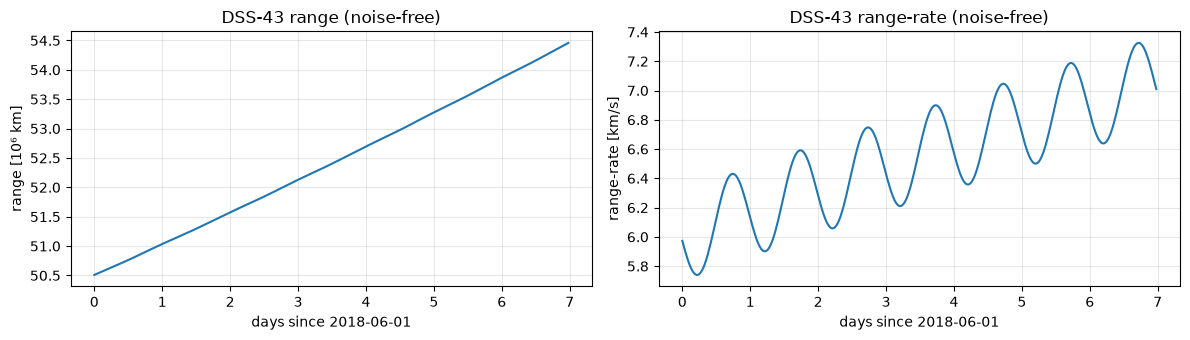

In [3]:
dss43_range, dss43_rangerate = models[2], models[3]

range_43 = dss43_range.computed_measurements(target=orex, epoch_array=epochs)[-1]
rangerate_43 = dss43_rangerate.computed_measurements(target=orex, epoch_array=epochs)[
    -1
]

days = (epochs - epochs[0]).convert_to(day).values
fig, ax = plt.subplots(1, 2, figsize=(12, 3.5))
ax[0].plot(days, range_43.quantity.convert_to(km).values / 1e6)
ax[0].set(
    xlabel="days since 2018-06-01",
    ylabel="range [10⁶ km]",
    title="DSS-43 range (noise-free)",
)
ax[1].plot(days, rangerate_43.quantity.values)
ax[1].set(
    xlabel="days since 2018-06-01",
    ylabel="range-rate [km/s]",
    title="DSS-43 range-rate (noise-free)",
)
for a in ax:
    a.grid(alpha=0.3)
plt.tight_layout()

The range grows by about 0.57 million km per day (range-rate of 6–7 km/s) as OSIRIS-REx and Earth separate. The range-rate carries a diurnal signature of roughly ±0.3 km/s from the station's motion with Earth's rotation; its amplitude and phase depend on the spacecraft's declination and right ascension, which is what makes range-rate from a single station sensitive to the plane-of-sky position.

## 3. Simulating tracking data

`MeasurementScheduler` turns a tracking plan into data files. Given the target, the window, the cadence and the elevation mask, each `schedule` request builds the epoch grid, keeps the epochs at which the station sees the spacecraft, evaluates the model there, adds Gaussian noise with the model's σ, writes the file and reads it back. It returns a `MeasurementSpec`, the filter's input ([chapter 5](05_filter_measurements.ipynb)). The models of section 1 are passed by type, station and σ.

The noise is drawn from NumPy's global random generator, so we seed it to make the dataset reproducible.
<div style="border-left:4px solid #9333ea; background:rgba(147,51,234,0.12); padding:6px 10px; border-radius:4px">
🟣 <b>QUESTION:</b> Here importing numpy only for this purpose... Can we make the measurement generation reproducible by passing a seed or sth?

In [4]:
import numpy as np

np.random.seed(2018)

scheduler = scb.MeasurementScheduler(
    target=orex,
    start=epochs,
    end=scb.SpiceManager.utc2et("2018-06-08T00:00:00"),
    cadence=scb.ArrayWUnits(30, minute),
    elevation_mask=10.0,
    noisy=True,
    output_dir=str(out),
)
tracking = scb.MeasurementSpec.many(*[
    scheduler.schedule(model.instrument, type(model), sigma=model.sigma, name=model.name,
                       dataset_name=model.name, file_name=model.name.replace(" ", "_"))
    for model in models
])

print(sorted(p.name for p in out.iterdir()))

['DSS-14_range-rate.json', 'DSS-14_range.json', 'DSS-43_range-rate.json', 'DSS-43_range.json', 'DSS-63_range-rate.json', 'DSS-63_range.json']


## 4. The measurement file

Each file is plain JSON. Observations are stored in a block (here `meas_sim`) with UTC time tags as year, day of year and seconds of day, the measured values, the SPICE ID of the station, and an outlier flag per observation:

In [5]:
record = scb.Utils.load_json(out / "DSS-43_range.json")

block = record["meas_sim"]
print("blocks:", [k for k in record if k != "name"])
for key, value in block.items():
    print(
        f"  {key:13s}",
        value[:3] if isinstance(value, list) else value,
        f"... ({len(value)} entries)" if isinstance(value, list) else "",
    )

blocks: ['meas_sim']
  year          [2018, 2018, 2018] ... (195 entries)
  doy           [152, 152, 152] ... (195 entries)
  sec           [18000.000005007, 19800.000005484, 21600.00000596] ... (195 entries)
  meas          [50614352.2459116, 50624683.95608957, 50635020.66862851] ... (195 entries)
  spice_id      399043 
  outlier_flag  [0.0, 0.0, 0.0] ... (195 entries)


Real DSN tracking data converted from TRK-2-34 files use the same record layout, one block per observable (e.g. `2W_doppler`, `2W_sranging`), plus auxiliary blocks for ramp tables, count times and calibrations. [Chapter 9](09_real_dsn_data.ipynb) reads such a file. Units are not stored in the file; they are supplied when the file is read.

## 5. Reading measurements back

`observed_measurements` reads one block (`meas_name`, default `"meas_sim"`) and returns an `ObsData` named tuple:

| Field | Content |
|---|---|
| `meas_time_et` | observation epochs (`EpochArray`, TDB) |
| `meas_sec` | seconds of day (UTC), as stored |
| `meas_obs` | observed values (`ArrayWFrame`) |
| `meas_outliers` | outlier flags |
| `aux_dict` | auxiliary data (real tracking files, chapter 9) |

Observations flagged as outliers in the file are excluded. Since each model knows its σ, the model's own units can be passed as the file units:

<div style="border-left:4px solid #9333ea; background:rgba(147,51,234,0.12); padding:6px 10px; border-radius:4px">
🟣 <b>QUESTION:</b> Better way to write/read meas files other than manually creating the file paths etc? Might be worth creating a measurements manager that can do measurements.write_all() or sth
</div>

In [6]:
observed = {
    model.name: model.observed_measurements(
        str(out / f"{model.name.replace(' ', '_')}.json"), units=model.sigma.units
    )
    for model in models
}

dss43 = observed["DSS-43 range"]
print("first epoch:", dss43.meas_time_et[0].to(rep="ISOC"))
print("first value:", dss43.meas_obs.quantity[0])

first epoch: 2018-06-01T05:01:09.1849 (TDB)
first value: 50614352.2459116 km


## 6. Tracking schedule

Each complex tracks only while the spacecraft is above 10° elevation. Range and range-rate share the same epochs, so the range datasets show the schedule:

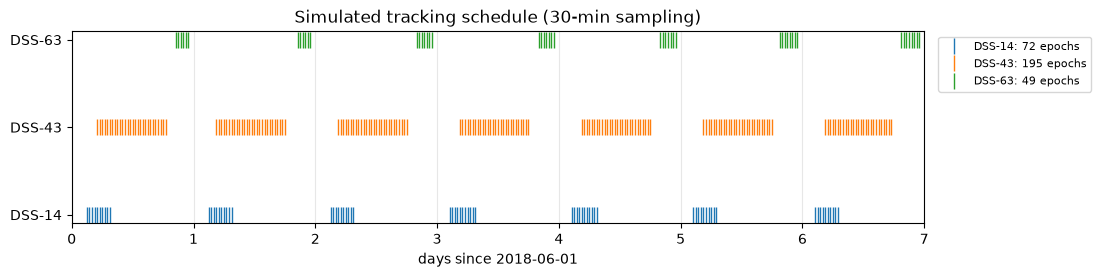

In [7]:
fig, ax = plt.subplots(figsize=(11, 2.5))
for row, dss in enumerate(stations):
    t_obs = observed[f"{dss} range"].meas_time_et
    t_days = (t_obs - epochs[0]).convert_to(day).values
    ax.plot(t_days, [row] * t_obs.size, "|", ms=12, label=f"{dss}: {t_obs.size} epochs")
ax.set(
    yticks=range(len(stations)),
    yticklabels=list(stations),
    xlabel="days since 2018-06-01",
    xlim=(0, 7),
    title="Simulated tracking schedule (30-min sampling)",
)
ax.legend(loc="upper left", bbox_to_anchor=(1.01, 1), fontsize=8)
ax.grid(axis="x", alpha=0.3)

The schedule mirrors the visibility analysis from [chapter 1](01_scenario.ipynb): long daily passes from Canberra, short ones from Goldstone and Madrid. The coverage gaps between passes are where the dynamics model has to carry the state.

## 7. Verifying the noise

The difference between the observed (noisy) values and the noise-free computed values, the O − C residual, should be zero-mean with a standard deviation equal to σ. `residuals` computes O − C for a model, with unit and frame checks:

dataset                 N mean/sigma std/sigma
DSS-14 range           72    -0.09    0.85
DSS-14 range-rate      72    -0.04    1.02
DSS-43 range          195    +0.06    1.04
DSS-43 range-rate     195    +0.06    0.93
DSS-63 range           49    +0.04    1.01
DSS-63 range-rate      49    +0.08    0.93


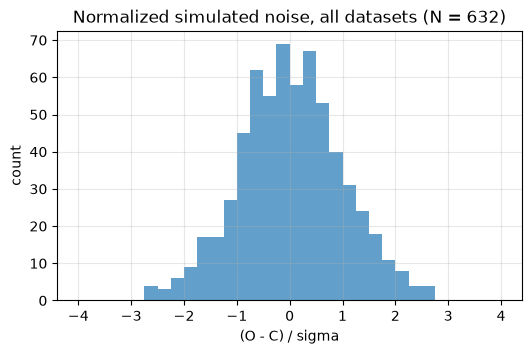

In [8]:
z_all = []
print(f"{'dataset':20s} {'N':>4s} {'mean/sigma':>10s} {'std/sigma':>9s}")
for model in models:
    obs = observed[model.name]
    computed = model.computed_measurements(target=orex, epoch_array=obs.meas_time_et)[-1]
    z = (model.residuals(obs.meas_obs, computed).quantity / model.sigma).values
    print(f"{model.name:20s} {z.size:4d} {z.mean():+8.2f} {z.std():7.2f}")
    z_all.extend(z)

fig, ax = plt.subplots(figsize=(6, 3.5))
ax.hist(z_all, bins=32, range=(-4, 4), color="tab:blue", alpha=0.7)
ax.set(
    xlabel="(O - C) / sigma",
    ylabel="count",
    title=f"Normalized simulated noise, all datasets (N = {len(z_all)})",
)
ax.grid(alpha=0.3)

All six datasets show unit-variance, zero-mean noise within sampling scatter.

## Summary

| Concept | Scarabaeus API |
|---|---|
| Measurement models | `RangeIdeal`, `RangeRateIdeal` (`name`, station, `sigma`) |
| Noise-free observables | `computed_measurements(target, epoch_array)` |
| Simulated tracking | `MeasurementScheduler(target, start, end, cadence, elevation_mask, noisy=True, output_dir)`, `schedule(station, model type, sigma=..., name=...)` → `MeasurementSpec`; per model: `write_observed_measurements(...)` |
| Measurement files | JSON blocks with UTC time tags, values, station ID, outlier flags |
| Reading observations | `observed_measurements(file, units=...)` → `ObsData` (`meas_time_et`, `meas_sec`, `meas_obs`, `meas_outliers`, `aux_dict`) |
| O − C | `residuals(observed, computed)` |

Six datasets, range and range-rate from DSS-14, DSS-43 and DSS-63, are saved in `outputs/03_tracking_data/`.

**Next:** [4. The filter's dynamics model](04_filter_dynamics.ipynb) sets up the reference trajectory, its initial uncertainty, and the state transition matrix the filter needs.